In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data=pd.read_csv("bank-full.csv",sep=";")

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
data.shape

(45211, 17)

In [ ]:
data.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [ ]:
data.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
data.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [ ]:
data["y"].value_counts()

,count
y,
no,39922
yes,5289


In [ ]:
numerical_features_1=data.select_dtypes(include=["int64","float64"]).columns
categorical_features_1=data.select_dtypes(include="object").columns

print(numerical_features_1)
print(categorical_features_1)

Index(['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous'], dtype='object')
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome', 'y'],
      dtype='object')


In [ ]:
categorical_features_1 = categorical_features_1.drop("y")

In [ ]:
correlation_matrix = data[numerical_features_1].corr()

print(correlation_matrix)

               age   balance       day  duration  campaign     pdays  previous
age       1.000000  0.097783 -0.009120 -0.004648  0.004760 -0.023758  0.001288
balance   0.097783  1.000000  0.004503  0.021560 -0.014578  0.003435  0.016674
day      -0.009120  0.004503  1.000000 -0.030206  0.162490 -0.093044 -0.051710
duration -0.004648  0.021560 -0.030206  1.000000 -0.084570 -0.001565  0.001203
campaign  0.004760 -0.014578  0.162490 -0.084570  1.000000 -0.088628 -0.032855
pdays    -0.023758  0.003435 -0.093044 -0.001565 -0.088628  1.000000  0.454820
previous  0.001288  0.016674 -0.051710  0.001203 -0.032855  0.454820  1.000000


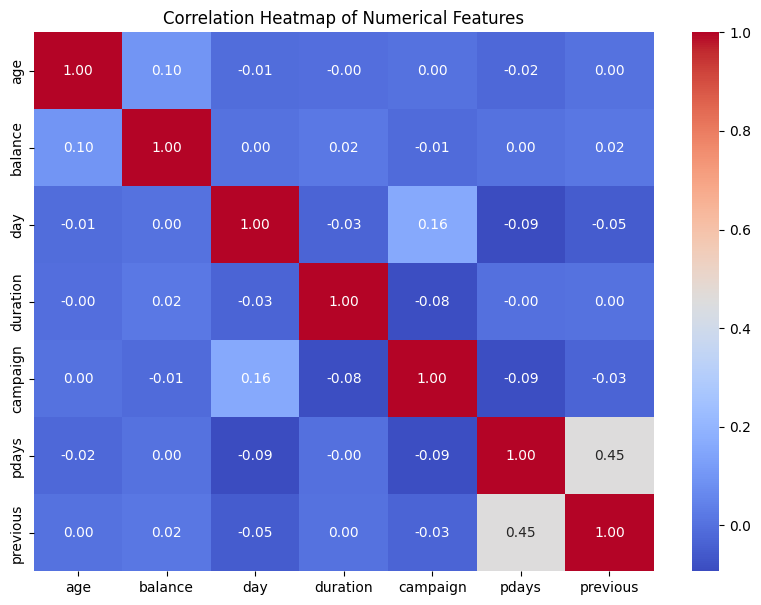

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

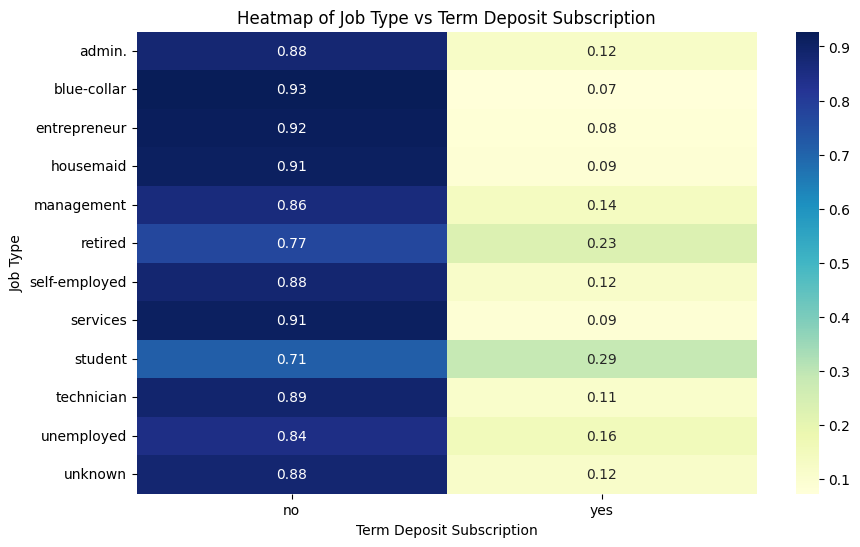

In [ ]:
categorical_heatmap = pd.crosstab(
    data["job"],
    data["y"],
    normalize="index"
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    categorical_heatmap,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("Heatmap of Job Type vs Term Deposit Subscription")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Job Type")

plt.show()

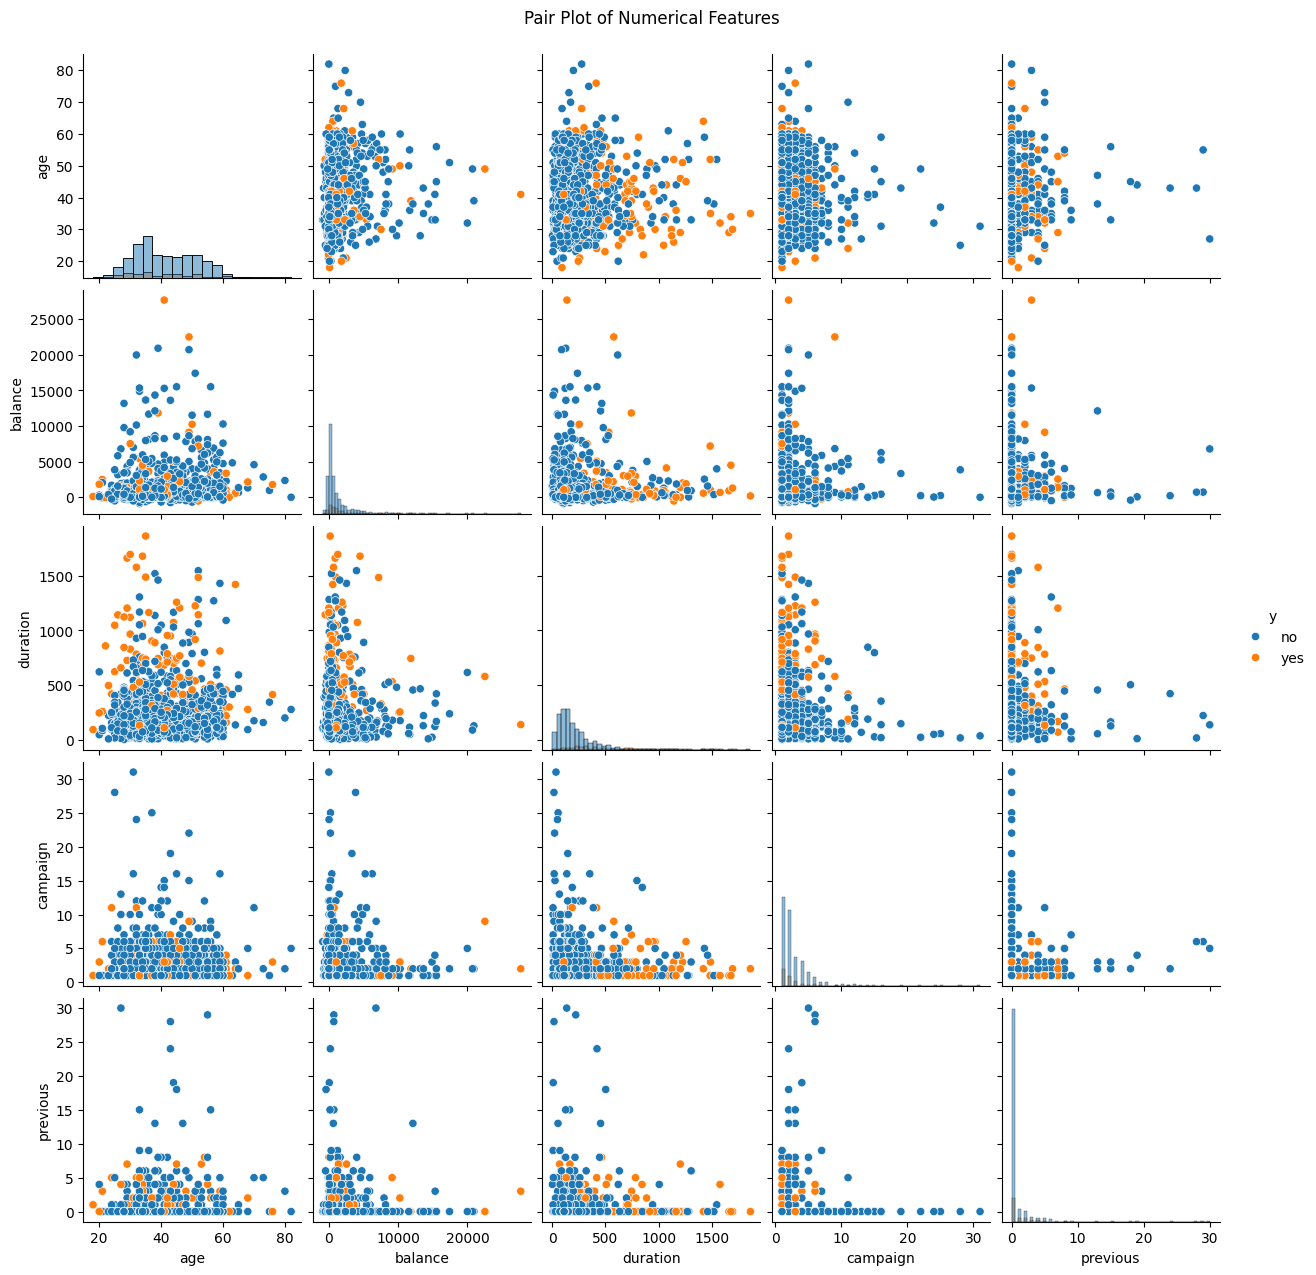

In [ ]:
pairplot_data = data[
    ["age", "balance", "duration", "campaign", "previous", "y"]
].sample(n=1000, random_state=42)

sns.pairplot(
    pairplot_data,
    hue="y",
    diag_kind="hist"
)

plt.suptitle(
    "Pair Plot of Numerical Features",
    y=1.02
)

plt.show()

In [ ]:
# Create a copy of the original dataset
data_clean = data.copy()

# Remove leading and trailing spaces from categorical values
for col in data_clean.select_dtypes(include="object").columns:
    data_clean[col] = data_clean[col].str.strip()

# Standardize target variable values
data_clean["y"] = data_clean["y"].str.lower()

# Remove duplicate records, if any
data_clean.drop_duplicates(inplace=True)

# Check missing values after cleaning
print("Missing Values:")
print(data_clean.isnull().sum().sum())

print("\nDuplicate Records:")
print(data_clean.duplicated().sum())

print("\nCleaned Dataset Shape:")
print(data_clean.shape)

Missing Values:
0

Duplicate Records:
0

Cleaned Dataset Shape:
(45211, 17)


In [ ]:
# Count unknown values in each column
for col in data.select_dtypes(include="object").columns:
    count = (data[col].str.lower() == "unknown").sum()

    if count > 0:
        print(col, ":", count)

job : 288
education : 1857
contact : 13020
poutcome : 36959


In [ ]:
# Replace unknown values in job and education with mode

for col in ["job", "education"]:
    mode_value = data_clean[col].mode()[0]
    data_clean[col] = data_clean[col].replace(
        "unknown", mode_value
    )

# Check unknown values after cleaning

for col in data_clean.select_dtypes(include="object").columns:
    count = (data_clean[col] == "unknown").sum()

    if count > 0:
        print(col, ":", count)

print("\nCleaned Dataset Shape:", data_clean.shape)

contact : 13020
poutcome : 36959

Cleaned Dataset Shape: (45211, 17)


In [ ]:
x = data_clean.drop("y", axis=1)

y = data_clean["y"].map({"no": 0,"yes": 1})

In [ ]:
print(x.shape)
print(y.shape)

(45211, 16)
(45211,)


In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (36168, 16)
Testing Data: (9043, 16)


In [ ]:
print("Duplicate Records:", data.duplicated().sum())

Duplicate Records: 0


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

# Identify numerical and categorical columns
numerical_columns = x.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = x.select_dtypes(
    include=["object"]
).columns.tolist()

# Apply preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(x_train)
X_test_processed = preprocessor.transform(x_test)

print("Processed Training Data:", X_train_processed.shape)
print("Processed Testing Data:", X_test_processed.shape)

Processed Training Data: (36168, 49)
Processed Testing Data: (9043, 49)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Train the model
baseline_model.fit(
    X_train_processed,
    y_train
)

# Make predictions
baseline_predictions = baseline_model.predict(
    X_test_processed
)

baseline_probabilities = baseline_model.predict_proba(
    X_test_processed
)[:, 1]

print("Baseline Model Trained Successfully")

Baseline Model Trained Successfully


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate evaluation metrics
baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_precision = precision_score(
    y_test, baseline_predictions
)

baseline_recall = recall_score(
    y_test, baseline_predictions
)

baseline_f1 = f1_score(
    y_test, baseline_predictions
)

baseline_auc = roc_auc_score(
    y_test, baseline_probabilities
)

# Display results
print("BASELINE MODEL PERFORMANCE")

print("Accuracy:", round(baseline_accuracy, 4))
print("Precision:", round(baseline_precision, 4))
print("Recall:", round(baseline_recall, 4))
print("F1 Score:", round(baseline_f1, 4))
print("ROC-AUC:", round(baseline_auc, 4))

BASELINE MODEL PERFORMANCE
Accuracy: 0.8464
Precision: 0.4192
Recall: 0.8119
F1 Score: 0.5529
ROC-AUC: 0.9074


In [ ]:
from sklearn.feature_selection import SelectKBest, chi2

# Select the top 20 features
feature_selector = SelectKBest(
    score_func=chi2,
    k=20
)

# Apply feature selection
X_train_selected = feature_selector.fit_transform(
    X_train_processed,
    y_train
)

X_test_selected = feature_selector.transform(
    X_test_processed
)

print("Original Number of Features:", X_train_processed.shape[1])
print("Selected Number of Features:", X_train_selected.shape[1])

Original Number of Features: 49
Selected Number of Features: 20


In [ ]:
feature_names = preprocessor.get_feature_names_out()

selected_features = feature_names[
    feature_selector.get_support()
]

print("Selected Features:")

for feature in selected_features:
    print(feature)

Selected Features:
num__duration
num__pdays
cat__job_blue-collar
cat__job_retired
cat__job_student
cat__marital_single
cat__education_tertiary
cat__housing_no
cat__housing_yes
cat__loan_yes
cat__contact_cellular
cat__contact_unknown
cat__month_apr
cat__month_dec
cat__month_mar
cat__month_may
cat__month_oct
cat__month_sep
cat__poutcome_success
cat__poutcome_unknown


In [ ]:
selected_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

# Train using selected features
selected_model.fit(
    X_train_selected,
    y_train
)

# Predict test data
selected_predictions = selected_model.predict(
    X_test_selected
)

selected_probabilities = selected_model.predict_proba(
    X_test_selected
)[:, 1]

print("Feature Selected Model Trained Successfully")

Feature Selected Model Trained Successfully


In [ ]:
# Calculate evaluation metrics
selected_accuracy = accuracy_score(
    y_test, selected_predictions
)

selected_precision = precision_score(
    y_test, selected_predictions
)

selected_recall = recall_score(
    y_test, selected_predictions
)

selected_f1 = f1_score(
    y_test, selected_predictions
)

selected_auc = roc_auc_score(
    y_test, selected_probabilities
)

# Display results
print("FEATURE SELECTED MODEL PERFORMANCE")

print("Accuracy:", round(selected_accuracy, 4))
print("Precision:", round(selected_precision, 4))
print("Recall:", round(selected_recall, 4))
print("F1 Score:", round(selected_f1, 4))
print("ROC-AUC:", round(selected_auc, 4))

FEATURE SELECTED MODEL PERFORMANCE
Accuracy: 0.8452
Precision: 0.4153
Recall: 0.793
F1 Score: 0.5452
ROC-AUC: 0.9031


In [ ]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Baseline Model": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_auc
    ],
    "Feature Selected Model": [
        selected_accuracy,
        selected_precision,
        selected_recall,
        selected_f1,
        selected_auc
    ]
})

print("MODEL PERFORMANCE COMPARISON")

display(comparison.round(4))

MODEL PERFORMANCE COMPARISON


,Metric,Baseline Model,Feature Selected Model
0,Accuracy,0.8464,0.8452
1,Precision,0.4192,0.4153
2,Recall,0.8119,0.7930
3,F1 Score,0.5529,0.5452
4,ROC-AUC,0.9074,0.9031


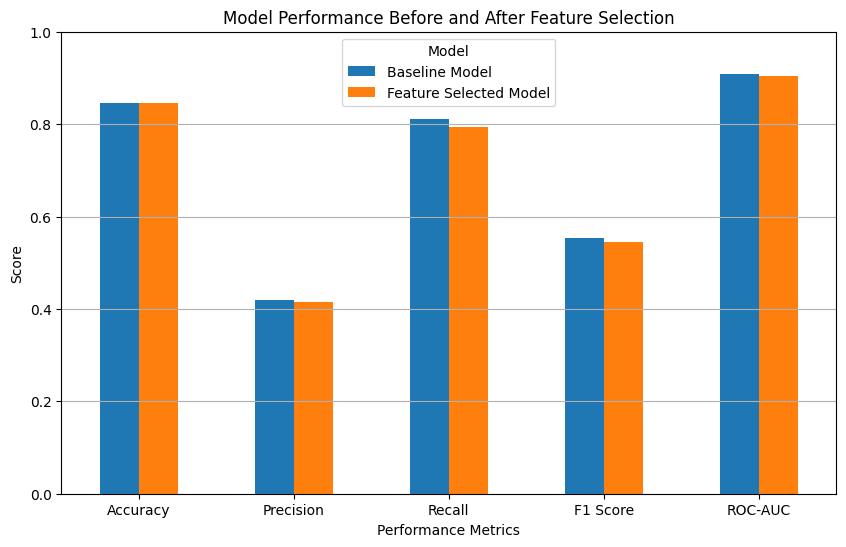

In [ ]:
comparison_plot = comparison.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Performance Before and After Feature Selection")
plt.xlabel("Performance Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y")

plt.show()